In [1]:
import os, copy, json, time, random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset, random_split
from torchvision import datasets
from torchvision.utils import make_grid
from torchmetrics.image import PeakSignalNoiseRatio, StructuralSimilarityIndexMeasure
from torchmetrics.image.fid import FrechetInceptionDistance

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")

cuda NVIDIA GeForce RTX 4060 Laptop GPU


In [2]:
MODEL_NAME = "dcgan"
DATA_DIR = "data"
CKPT_DIR = "checkpoints"
FIG_DIR = "figures"
RESULTS_DIR = "results"
for d in (DATA_DIR, CKPT_DIR, FIG_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)

BATCH_SIZE = 128
ORIGINAL_DIM = 28 * 28
NOISE_DIM = 100
MAX_EPOCHS = 30
LEARN_RATE = 2e-4
BETAS = (0.5, 0.999)

In [3]:
train_raw = datasets.FashionMNIST(DATA_DIR, train=True, download=True)
test_raw = datasets.FashionMNIST(DATA_DIR, train=False, download=True)
images = torch.cat([train_raw.data, test_raw.data]).unsqueeze(1).float() / 255.0
labels = torch.cat([train_raw.targets, test_raw.targets])
full = TensorDataset(images, labels)

n_train, n_val = int(0.8 * len(full)), int(0.1 * len(full))
n_test = len(full) - n_train - n_val
train_set, val_set, test_set = random_split(
    full, [n_train, n_val, n_test], generator=torch.Generator().manual_seed(SEED))

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)

CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
test_targets = labels[torch.tensor(test_set.indices)]
VIS_IDX = [int(torch.nonzero(test_targets == c)[0]) for c in range(10)]
x_vis = torch.stack([test_set[i][0] for i in VIS_IDX])
x_a, x_b = x_vis[1:2], x_vis[9:10]
ALPHAS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
print(f"train={len(train_set)}  val={len(val_set)}  test={len(test_set)}")

train=56000  val=7000  test=7000


In [4]:
def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()


@torch.no_grad()
def reconstruction_metrics(reconstruct, loader):
    psnr = PeakSignalNoiseRatio(data_range=1.0).to(device)
    ssim = StructuralSimilarityIndexMeasure(data_range=1.0).to(device)
    se, count = 0.0, 0
    for x, _ in loader:
        x = x.to(device)
        x_hat = reconstruct(x).clamp(0, 1)
        se += F.mse_loss(x_hat, x, reduction="sum").item()
        count += x.numel()
        psnr.update(x_hat, x)
        ssim.update(x_hat, x)
    return {"test_mse": se / count, "test_psnr": psnr.compute().item(), "test_ssim": ssim.compute().item()}


@torch.no_grad()
def compute_fid(generate, n_samples=len(test_set), batch=250):
    fid = FrechetInceptionDistance(feature=2048, normalize=True).to(device)
    for x, _ in test_loader:
        fid.update(x.to(device).repeat(1, 3, 1, 1), real=True)
    done = 0
    while done < n_samples:
        b = min(batch, n_samples - done)
        fid.update(generate(b).clamp(0, 1).repeat(1, 3, 1, 1), real=False)
        done += b
    return fid.compute().item()


@torch.no_grad()
def measure_latency(fn, n_warmup=5, n_runs=20):
    for _ in range(n_warmup):
        fn()
    sync()
    start = time.perf_counter()
    for _ in range(n_runs):
        fn()
    sync()
    return (time.perf_counter() - start) / n_runs * 1000


def show_grid(images, nrow, title=None):
    grid = make_grid(images.detach().cpu().clamp(0, 1), nrow=nrow, padding=2, pad_value=1.0)
    plt.figure(figsize=(grid.shape[2] / 40, grid.shape[1] / 40))
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis("off")
    if title:
        plt.title(title)
    plt.show()


def plot_history(history, keys):
    plt.figure(figsize=(6, 3.5))
    for k in keys:
        plt.plot(range(1, len(history[k]) + 1), history[k], label=k)
    plt.xlabel("epoch")
    plt.ylabel("loss")
    plt.legend()
    plt.show()


def save_results(results, outputs):
    with open(os.path.join(RESULTS_DIR, f"{MODEL_NAME}.json"), "w") as f:
        json.dump(results, f, indent=2)
    torch.save(outputs, os.path.join(RESULTS_DIR, f"{MODEL_NAME}_outputs.pt"))


def print_results(results):
    print(json.dumps({k: v for k, v in results.items() if k != "loss_history"}, indent=2))


x_latency = next(iter(test_loader))[0][:64].to(device)

In [5]:
class Generator(nn.Module):
    def __init__(self, ngf=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(NOISE_DIM, ngf * 4, 7, 1, 0, bias=False),
            nn.BatchNorm2d(ngf * 4),
            nn.ReLU(True),
            nn.ConvTranspose2d(ngf * 4, ngf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 2),
            nn.ReLU(True),
            nn.ConvTranspose2d(ngf * 2, 1, 4, 2, 1, bias=False),
            nn.Tanh())

    def forward(self, z):
        return self.net(z.view(-1, NOISE_DIM, 1, 1))


class Discriminator(nn.Module):
    def __init__(self, ndf=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, ndf, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, True),
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 2),
            nn.LeakyReLU(0.2, True),
            nn.Conv2d(ndf * 2, 1, 7, 1, 0, bias=False),
            nn.Flatten())

    def forward(self, x):
        return self.net(x)


def init_weights(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.zeros_(m.bias)

In [6]:
def discriminator_loss(real_output, fake_output):
    real_loss = F.binary_cross_entropy_with_logits(real_output, torch.ones_like(real_output))
    fake_loss = F.binary_cross_entropy_with_logits(fake_output, torch.zeros_like(fake_output))
    return real_loss + fake_loss


def generator_loss(fake_output):
    return F.binary_cross_entropy_with_logits(fake_output, torch.ones_like(fake_output))


def train(generator, discriminator, g_optimizer, d_optimizer, real):
    noise = torch.randn(real.size(0), NOISE_DIM, device=device)
    fake = generator(noise)

    real_output = discriminator(real)
    fake_output = discriminator(fake.detach())
    d_loss = discriminator_loss(real_output, fake_output)
    d_optimizer.zero_grad()
    d_loss.backward()
    d_optimizer.step()

    g_loss = generator_loss(discriminator(fake))
    g_optimizer.zero_grad()
    g_loss.backward()
    g_optimizer.step()

    return (d_loss.item(), g_loss.item(),
            torch.sigmoid(real_output).mean().item(), torch.sigmoid(fake_output).mean().item())


def train_gan_loop(generator, discriminator, g_optimizer, d_optimizer, loader, epochs):
    history = {"d_loss": [], "g_loss": [], "d_real": [], "d_fake": []}
    epoch_times = []
    for epoch in range(epochs):
        generator.train()
        discriminator.train()
        epoch_values = {k: [] for k in history}
        sync()
        start = time.perf_counter()
        for x, _ in loader:
            real = x.to(device) * 2 - 1
            values = train(generator, discriminator, g_optimizer, d_optimizer, real)
            for k, v in zip(history, values):
                epoch_values[k].append(v)
        sync()
        epoch_times.append(time.perf_counter() - start)

        for k in history:
            history[k].append(float(np.mean(epoch_values[k])))
        print(f"Epoch[{epoch + 1} / {epochs}], D Loss : {history['d_loss'][-1]:.4f}, "
              f"G Loss : {history['g_loss'][-1]:.4f}, D(x) : {history['d_real'][-1]:.3f}, "
              f"D(G(z)) : {history['d_fake'][-1]:.3f}, Time : {epoch_times[-1]:.1f}s")
    return history, epoch_times

In [7]:
generator = Generator().to(device)
discriminator = Discriminator().to(device)
generator.apply(init_weights)
discriminator.apply(init_weights)
g_optimizer = torch.optim.Adam(generator.parameters(), lr=LEARN_RATE, betas=BETAS)
d_optimizer = torch.optim.Adam(discriminator.parameters(), lr=LEARN_RATE, betas=BETAS)
print(generator)
print(discriminator)

history, epoch_times = train_gan_loop(generator, discriminator, g_optimizer, d_optimizer,
                                      train_loader, MAX_EPOCHS)
torch.save({"generator": generator.state_dict(), "discriminator": discriminator.state_dict()},
           os.path.join(CKPT_DIR, f"{MODEL_NAME}.pt"))

Generator(
  (net): Sequential(
    (0): ConvTranspose2d(100, 256, kernel_size=(7, 7), stride=(1, 1), bias=False)
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(128, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): Tanh()
  )
)
Discriminator(
  (net): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Conv2d(128, 1, kern

Epoch[1 / 30], D Loss : 0.6518, G Loss : 1.7073, D(x) : 0.753, D(G(z)) : 0.264, Time : 5.1s


Epoch[2 / 30], D Loss : 0.6190, G Loss : 1.8025, D(x) : 0.758, D(G(z)) : 0.239, Time : 4.9s


Epoch[3 / 30], D Loss : 0.8577, G Loss : 1.4882, D(x) : 0.683, D(G(z)) : 0.316, Time : 4.8s


Epoch[4 / 30], D Loss : 0.9469, G Loss : 1.3098, D(x) : 0.652, D(G(z)) : 0.347, Time : 4.8s


Epoch[5 / 30], D Loss : 0.9905, G Loss : 1.2824, D(x) : 0.642, D(G(z)) : 0.357, Time : 5.0s


... (21 outputs left out)

Epoch[27 / 30], D Loss : 1.1929, G Loss : 1.0814, D(x) : 0.582, D(G(z)) : 0.418, Time : 4.8s


Epoch[28 / 30], D Loss : 1.1953, G Loss : 1.0715, D(x) : 0.581, D(G(z)) : 0.419, Time : 4.9s


Epoch[29 / 30], D Loss : 1.1874, G Loss : 1.0732, D(x) : 0.582, D(G(z)) : 0.418, Time : 6.0s


Epoch[30 / 30], D Loss : 1.1951, G Loss : 1.0839, D(x) : 0.582, D(G(z)) : 0.418, Time : 6.2s


In [8]:
generator.eval()
generate = lambda n: (generator(torch.randn(n, NOISE_DIM, device=device)) + 1) / 2
results = {"model": MODEL_NAME, "latent_dim": NOISE_DIM,
           "train_time_per_epoch_s": float(np.mean(epoch_times)),
           "test_mse": None, "test_psnr": None, "test_ssim": None}
results["latency_ms_batch64"] = measure_latency(lambda: generate(64))
results["fid"] = compute_fid(generate)
results["loss_history"] = history
print_results(results)

{
  "model": "dcgan",
  "latent_dim": 100,
  "train_time_per_epoch_s": 4.916621663333342,
  "test_mse": null,
  "test_psnr": null,
  "test_ssim": null,
  "latency_ms_batch64": 1.252199999998993,
  "fid": 21.74233627319336
}


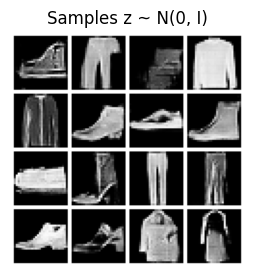

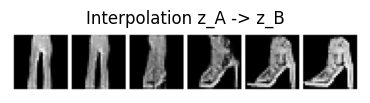

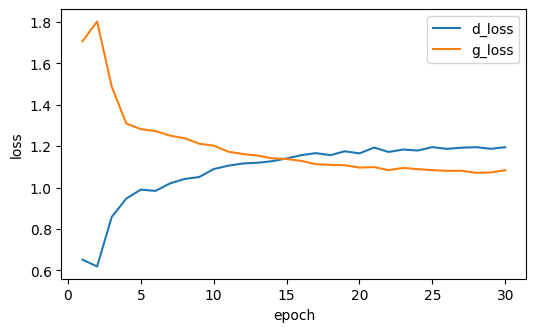

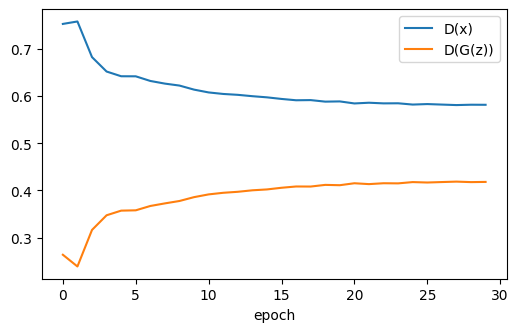

In [9]:
g = torch.Generator().manual_seed(SEED)
z_fixed = torch.randn(16, NOISE_DIM, generator=g).to(device)
z_pool = torch.randn(2000, NOISE_DIM, generator=g).to(device)
with torch.no_grad():
    pool = ((generator(z_pool) + 1) / 2).flatten(1)
nearest = lambda x: z_pool[((pool - x.to(device).flatten(1)) ** 2).mean(1).argmin()].unsqueeze(0)
z_a, z_b = nearest(x_a), nearest(x_b)
with torch.no_grad():
    samples = ((generator(z_fixed) + 1) / 2).cpu()
    interp = ((generator(torch.cat([(1 - a) * z_a + a * z_b for a in ALPHAS])) + 1) / 2).cpu()

show_grid(samples, nrow=4, title="Samples z ~ N(0, I)")
show_grid(interp, nrow=len(ALPHAS), title="Interpolation z_A -> z_B")
plot_history(history, ["d_loss", "g_loss"])
plt.figure(figsize=(6, 3.5))
plt.plot(history["d_real"], label="D(x)")
plt.plot(history["d_fake"], label="D(G(z))")
plt.xlabel("epoch")
plt.legend()
plt.show()

In [10]:
save_results(results, {"samples": samples, "interp": interp})